# Exploration 7: Eigenvalues and Eigenvectors

**Name:** Lay Shah

In this exploration we'll use [panchi](https://github.com/Gustavo-Galvao-e-Silva/panchi) to **see** eigenvectors. An eigenvector of $A$ is a non-zero vector $\vec v$ that $A$ only stretches, shrinks or flips: $A\vec v = \lambda \vec v$, so $A\vec v$ stays on the same line as $\vec v$. The number $\lambda$ is its **eigenvalue**.

You'll find eigenvectors by **watching** transformations and **testing** guesses, not by calculating them. No formulas are needed in the code: you'll only ever type numbers.

**Every problem has three steps:**

- **Predict:** before running any code, write down what you think will happen. Predictions are graded on being *written first*, not on being right.
- **Run:** run the code. Until the final challenge, you only ever need to choose numbers; the code is written for you.
- **Explain:** compare what happened with your prediction and explain it in a sentence or two.

**How to complete this exploration**

1. Open the notebook in Google Colab and choose **File → Save a copy in Drive**, then work in that copy. (Skip this if the notebook was handed to you as your own copy, e.g. through Google Classroom.)
2. **Run the setup cell below once before beginning.** Then run the rest of the cells **from top to bottom**. Click a cell and press **Shift + Enter** to run it.
3. Wherever you see `___`, replace it with your answer and run the cell again.
4. Answer the written questions by double-clicking the *Your answer* cells and typing.
5. When you're done, run the **Export to PDF** cell at the very end and submit the PDF.

### Python in 60 seconds

- `x = 5` **stores** the value `5` under the name `x`. From then on, `x` means `5`.
- `print(x)` shows a value below the cell.
- Lines starting with `#` are **comments**. Python ignores them; they're notes for you.
- Python counts from **0**, not 1. The first row of a matrix is row `0`, the second is row `1`, and so on.
- `[1, 2]` is a **list** of numbers. We'll use lists to type vectors, like `[1, -1]` for $\begin{bmatrix}1\\-1\end{bmatrix}$.
- If a cell says *"This cell still has a ___ blank"*, there's still something to fill in!
- Errors are normal and nothing breaks: read the last line of the message, fix the cell, and run it again.

## ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️

Click the ▶ button on the cell below. It takes about 30 seconds:

- A window will pop up asking for permission to access your **Google Drive**. Allow it, so the export cell at the end can find your saved notebook.
- Only run it **once**. Run it again only if Colab disconnects or you come back in a new session.

In [1]:
# @title ⚠️ RUN THIS SETUP CELL ONCE BEFORE BEGINNING THE EXPLORATION ⚠️
# @markdown Only change this if you **renamed** your notebook:
NOTEBOOK_NAME = "exploration_eigenvalues"  # @param {type:"string"}
# @markdown Pick how transformations are animated. **manim** looks nicer, but setup takes 3 to 5 extra minutes:
ANIMATIONS = "manim"  # @param ["matplotlib", "manim"]

import glob
import io
import os
import tokenize

# 1. Connect your Google Drive (a permission window will pop up)
from google.colab import drive

drive.mount("/content/drive")
MY_DRIVE = "/content/drive/MyDrive"

# 2. Install panchi (and manim, if you picked it)
%pip install -q "panchi>=3.1"
if ANIMATIONS == "manim":
    print("Installing manim. This takes a few minutes...")
    !apt-get update -qq > /dev/null
    !DEBIAN_FRONTEND=noninteractive apt-get install -y -qq libcairo2-dev libpango1.0-dev ffmpeg texlive-latex-extra texlive-fonts-recommended > /dev/null
    %pip install -q "panchi[manim]>=3.1"


# 3. Find your saved copy of this notebook in Drive, even if it's called "Copy of ..."
#    or has your name in front (the most recently saved one wins)
def find_notebook():
    found = []
    for folder in ["Colab Notebooks", "Classroom"]:
        found += glob.glob(f"{MY_DRIVE}/{folder}/**/*{NOTEBOOK_NAME}*.ipynb", recursive=True)
    return max(found, key=os.path.getmtime) if found else None


# 4. Friendly reminder instead of a confusing error when a cell still has a ___ blank
#    (IPython normally uses ___ as a name for an old output, so blanks wouldn't fail)
def _check_blanks(lines):
    try:
        tokens = tokenize.generate_tokens(io.StringIO("".join(lines)).readline)
        has_blank = any(t.type == tokenize.NAME and t.string == "___" for t in tokens)
    except Exception:
        return lines
    if has_blank:
        return ['print("This cell still has a ___ blank. '
                'Replace every ___ with your answer, then run it again.")\n']
    return lines


transformers = get_ipython().input_transformers_cleanup
transformers[:] = [t for t in transformers if getattr(t, "__name__", "") != "_check_blanks"]
transformers.append(_check_blanks)


# 5. Helpers for testing eigenvector guesses
import panchi as pan
from panchi.visualizations import Animator2D, Animator3D

# Animations can't go in the PDF, so the PDF shows this note instead
def _pdf_note(self):
    return "(Animation: plays in Colab, not in the PDF.)"


try:
    from panchi.visualizations.backends.matplotlib_base import _InlineAnimation

    _InlineAnimation.__repr__ = _pdf_note
except ImportError:
    pass

if ANIMATIONS == "manim":
    import manim

    manim.config.verbosity = "WARNING"  # hide manim's progress messages
    manim.config.progress_bar = "none"
    # The zero transformation shrinks arrows to nothing, which makes manim warn
    import warnings

    warnings.filterwarnings("ignore", message="put_start_and_end_on")
    try:
        from panchi.visualizations.backends.manim_base import _ManimOutput

        _ManimOutput.__repr__ = _pdf_note
    except ImportError:
        pass

_plot2d = Animator2D(figsize=(4, 4))
_plot3d = Animator3D(figsize=(5, 5))


def _exact(x):
    # Keeps typed decimals like 0.5 exact; leaves floats from cos/sin alone
    return x if isinstance(x, float) else pan.Fraction(str(x))


def _vector(v):
    return pan.Vector([_exact(x) for x in v])


def _close(a, b):
    return abs(a - b) < 1e-9 if isinstance(a, float) or isinstance(b, float) else a == b


def _nice(x):
    return round(x, 4) + 0.0 if isinstance(x, float) else x


def try_vector(A, v):
    """Plot v and Av, and say whether Av is a multiple of v."""
    v = _vector(v)
    Av = A @ v
    if all(x == 0 for x in v):
        print("v is the zero vector, which never counts as an eigenvector. Try another v.")
        return
    i = next(k for k, x in enumerate(v) if x != 0)
    c = Av[i] / v[i]
    plot = _plot2d if len(v) == 2 else _plot3d
    plot.plot_vectors([Av, v], labels=["Av", "v"], colors=["red", "blue"])  # v on top
    print("v  =", v)
    print("Av =", pan.Vector([_nice(x) for x in Av]))
    if all(_close(a, c * b) for a, b in zip(Av, v)):
        print(f"Av = {_nice(c)} * v, so v IS an eigenvector, with eigenvalue {_nice(c)}.")
    else:
        print("Av is not a multiple of v, so v is NOT an eigenvector.")


def check_answers(A, pairs):
    """Check your (eigenvalue, eigenvector) pairs and count how many eigenvalues you found."""
    real = [
        value for value in pan.eigen(A).eigenvalues
        if not isinstance(value, pan.symbolic.QuadraticNumber) or value.is_real
    ]
    found = []
    for value, v in pairs:
        value, v = _exact(value), _vector(v)
        ok = any(x != 0 for x in v) and A @ v == value * v
        print(f"eigenvalue {value}, eigenvector {v}:", "correct!" if ok else "not an eigenpair.")
        if ok and value not in found:
            found.append(value)
    if not real:
        print("This matrix has no real eigenvalues, so there are none to find.")
    elif len(found) == len(real):
        print(f"You found all of this matrix's real eigenvalues ({len(real)} in total). Nice!")
    else:
        print(f"You found {len(found)} of this matrix's {len(real)} real eigenvalue(s). Keep looking!")

if find_notebook():
    print("Setup complete! You can start the exploration now.")
else:
    print("Setup complete, but your saved copy of this notebook wasn't found in Drive.")
    print("Choose File > Save a copy in Drive, then work in (and run setup in) that copy.")

Mounted at /content/drive
Setup complete, but your saved copy of this notebook wasn't found in Drive.
Choose File > Save a copy in Drive, then work in (and run setup in) that copy.


In [2]:
import panchi as pan
from panchi.algorithms import RowAdd, RowScale, RowSwap
from panchi.visualizations import Animator2D, Animator3D

# ANIMATIONS is "matplotlib" or "manim", whichever you picked in the setup cell
animator = Animator2D(backend=ANIMATIONS, figsize=(5, 5))
animator3d = Animator3D(backend=ANIMATIONS, figsize=(5, 5))

### Your three tools

- `animator.animate_transform(A, vectors=[...])` **animates** $A$: the grid bends and each vector slides to where $A$ sends it. **Eigenvectors are the arrows that stay on their own line** (the line through $\vec 0$ and the arrow).
- `try_vector(A, [x, y])` **tests** one guess: it draws $\vec v$ (blue) and $A\vec v$ (red) and says whether $A\vec v$ is a multiple of $\vec v$.
- `check_answers(A, [(eigenvalue, [x, y]), ...])` **checks** your final answers and tells you how many of $A$'s real eigenvalues you found (but not what the missing ones are!).

Animations are drawn with **matplotlib** unless you picked **manim** in the setup cell (to switch, change the dropdown there and run the setup cell again). Either way, the animations don't show up in the PDF, so always write your answers in the text cells.

**Do not use `pan.eigen()` or `pan.eigen_qr()` anywhere in this exploration.** The point is to find eigenvectors by looking!

## Problem 1. Warm-up: which arrows stay on their line?

Let $A = \begin{bmatrix}1 & 2\\ 2 & 1\end{bmatrix}$. The animation below shows what $A$ does to $\begin{bmatrix}1\\1\end{bmatrix}$, $\begin{bmatrix}1\\-1\end{bmatrix}$, and a vector **you** choose.

Pick your vector by replacing the blanks (whole numbers, not a multiple of the other two), then run the cell and watch closely.

In [3]:
A = pan.Matrix([[1, 2], [2, 1]])

my_vector = [1, 0]

animator.animate_transform(A, vectors=[pan.Vector([1, 1]), pan.Vector([1, -1]), pan.Vector(my_vector)])

(Animation: plays in Colab, not in the PDF.)

**Predict:** which of the three arrows stayed on their own line? For those, was the arrow stretched, shrunk, or flipped, and by how much? That number is the eigenvalue.

I predict [1,1] stays on its line (and it gets stretched by 3). I predict [1, -1] stays on its line, and it flips to point the opposite way with the same length. I predict [1,0] gets knocked off its line.

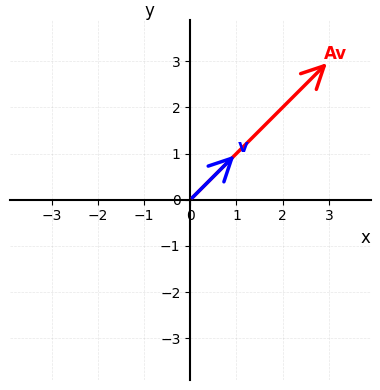

v  = [1, 1]
Av = [3, 3]
Av = 3 * v, so v IS an eigenvector, with eigenvalue 3.


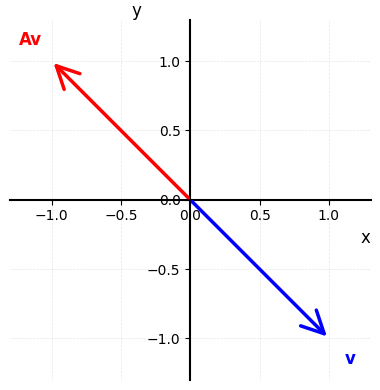

v  = [1, -1]
Av = [-1, 1]
Av = -1 * v, so v IS an eigenvector, with eigenvalue -1.


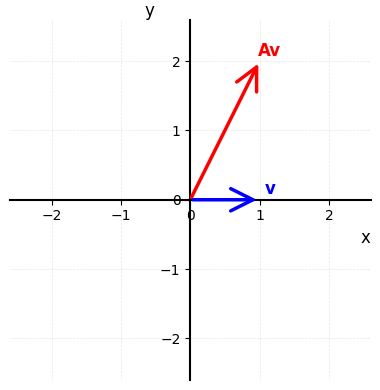

v  = [1, 0]
Av = [1, 2]
Av is not a multiple of v, so v is NOT an eigenvector.


In [4]:
try_vector(A, [1, 1])
try_vector(A, [1, -1])
try_vector(A, [1, 0])

**Explain:** were your predictions right? Why is your vector not an eigenvector, even though it is a combination of the other two?

Yes my predictions were right. my vector is not an eigenvector since A stretches it's [1, 1] part by 3 but flips its [1, -1] part by -1. Since the two parts get scaled by differenta mounts, the mix changes and the result [1, 2] points in a new direction instead of staying in the line of [1, 0].

## Problem 2. Eigenvectors from geometry

Each matrix below does something you can picture. For each one:

1. **Predict** the eigenvalues and an eigenvector for each, **just by thinking** about what the transformation does.
2. Type a guessed **eigenvector** `v` and a vector `w` that is **not** an eigenvector, then watch the animation.
3. Test both with `try_vector`.
4. Write your eigenpairs into `check_answers`. If you have only one pair, delete the second line; if you have more, copy a line.

### (a)

$A = \begin{bmatrix}0 & 0\\ 0 & 0\end{bmatrix}$, the **zero transformation**: every vector goes to $\vec 0$.

**Predict:** the eigenvalue(s) and an eigenvector for each.

every nonzero vector is an eigenvector wiht eigenvalue 0, sicne eveyrthing goes to the xero vector

In [5]:
A = pan.Matrix([[0, 0], [0, 0]])

v = [1, 0]  # your guessed eigenvector
w = [0, 1]  # a vector that is NOT an eigenvector

animator.animate_transform(A, vectors=[pan.Vector(v), pan.Vector(w)])

(Animation: plays in Colab, not in the PDF.)

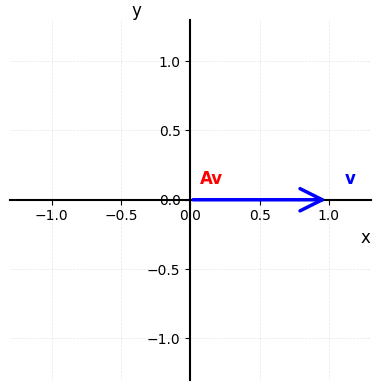

v  = [1, 0]
Av = [0, 0]
Av = 0 * v, so v IS an eigenvector, with eigenvalue 0.


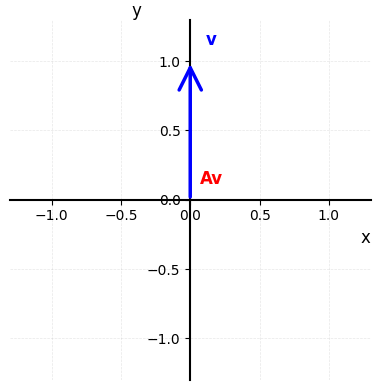

v  = [0, 1]
Av = [0, 0]
Av = 0 * v, so v IS an eigenvector, with eigenvalue 0.


In [6]:
try_vector(A, v)
try_vector(A, w)

In [7]:
check_answers(A, [
    (0, [1, 0]),  # (eigenvalue, eigenvector)
    (0, [0, 1]),
])

eigenvalue 0, eigenvector [1, 0]: correct!
eigenvalue 0, eigenvector [0, 1]: correct!
You found all of this matrix's real eigenvalues (1 in total). Nice!


**Explain:** which vectors are eigenvectors of the zero transformation, and why? Could you even pick a `w` that is *not* one?

every nonzero vector is an eigenvector with eigenvalue zero, sicne A sends everything to the zero vector. which is just 0 times the original. So no, you can't pick a w that isn't one.

### (b)

$A = \begin{bmatrix}1/2 & 1/2\\ 1/2 & 1/2\end{bmatrix}$, **projection** onto the line $x_1 = x_2$.

**Predict:** the eigenvalue(s) and an eigenvector for each.

[1,1] with eigenval of 1 and [1,-1] with eigenval of 0.

In [8]:
half = pan.Fraction(1, 2)
A = pan.Matrix([[half, half], [half, half]])

v = [1, 1]  # your guessed eigenvector
w = [1, 0]  # a vector that is NOT an eigenvector

animator.animate_transform(A, vectors=[pan.Vector(v), pan.Vector(w)])

(Animation: plays in Colab, not in the PDF.)

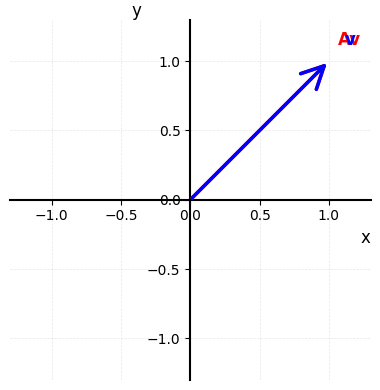

v  = [1, 1]
Av = [1, 1]
Av = 1 * v, so v IS an eigenvector, with eigenvalue 1.


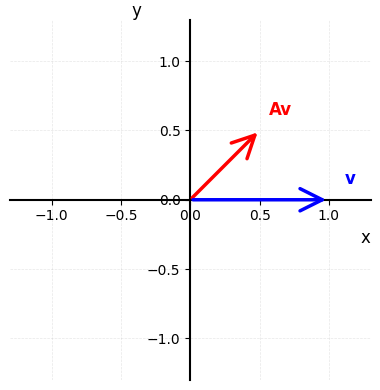

v  = [1, 0]
Av = [1/2, 1/2]
Av is not a multiple of v, so v is NOT an eigenvector.


In [9]:
try_vector(A, v)
try_vector(A, w)

In [10]:
check_answers(A, [
    (1, [1, 1]),  # (eigenvalue, eigenvector)
    (0, [1, -1]),
])

eigenvalue 1, eigenvector [1, 1]: correct!
eigenvalue 0, eigenvector [1, -1]: correct!
You found all of this matrix's real eigenvalues (2 in total). Nice!


**Explain:** what happens to vectors *on* the line $x_1 = x_2$? What happens to vectors *perpendicular* to it?

Vectors on the line are already there, so the projection leaves them alone. Vectors perpendicular to it get squished to zero.

### (c)

$A = \begin{bmatrix}0 & 3\\ 3 & 0\end{bmatrix}$, **reflect** about the line $x_1 = x_2$ and **stretch** by a factor of 3.

**Predict:** the eigenvalue(s) and an eigenvector for each.

[1, 1] with eigenval of 3 and [1, -1] with eigenval of -3

In [39]:
A = pan.Matrix([[0, 3], [3, 0]])

v = [1, 1]  # your guessed eigenvector
w = [1, 0]  # a vector that is NOT an eigenvector

animator.animate_transform(A, vectors=[pan.Vector(v), pan.Vector(w)])

(Animation: plays in Colab, not in the PDF.)

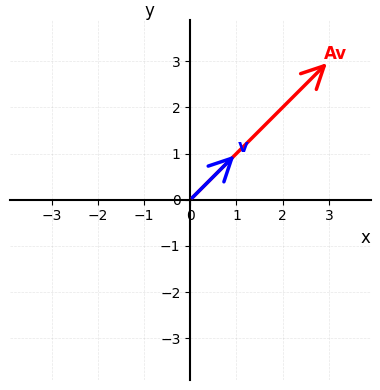

v  = [1, 1]
Av = [3, 3]
Av = 3 * v, so v IS an eigenvector, with eigenvalue 3.


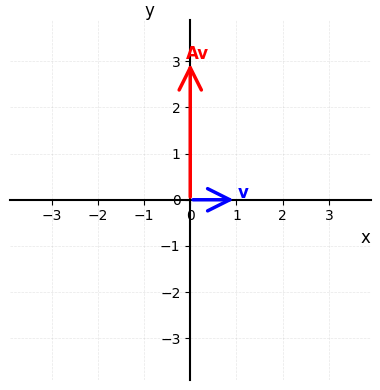

v  = [1, 0]
Av = [0, 3]
Av is not a multiple of v, so v is NOT an eigenvector.


In [12]:
try_vector(A, v)
try_vector(A, w)

In [40]:
check_answers(A, [
       (3, [1, 1]),
       (-3, [1, -1]),
   ])

eigenvalue 3, eigenvector [1, 1]: correct!
eigenvalue -3, eigenvector [1, -1]: correct!
You found all of this matrix's real eigenvalues (2 in total). Nice!


**Explain:** which line does the reflection leave alone, and which line does it flip? How does the stretch by 3 change the eigenvalues?

The reflection leaves the line x1 = x2 alone and flips the perpsndicular line (x1 = -x2). Stretching by 3 miltuiplies both eigenvalues by 3, giving 3 and -3.

### (d)

$A = \begin{bmatrix}1 & 0\\ 1 & 1\end{bmatrix}$, a **shear**.

**Predict:** the eigenvalue(s) and an eigenvector for each.

[0, 1] with eigenval of 1

In [14]:
A = pan.Matrix([[1, 0], [1, 1]])

v = [0, 1]  # your guessed eigenvector
w = [1, 0]  # a vector that is NOT an eigenvector

animator.animate_transform(A, vectors=[pan.Vector(v), pan.Vector(w)])

(Animation: plays in Colab, not in the PDF.)

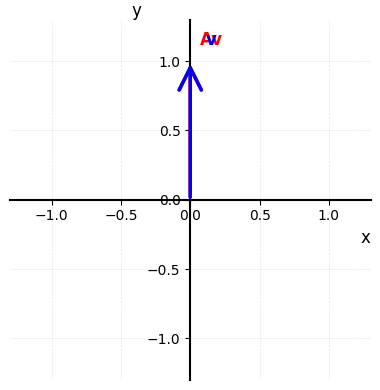

v  = [0, 1]
Av = [0, 1]
Av = 1 * v, so v IS an eigenvector, with eigenvalue 1.


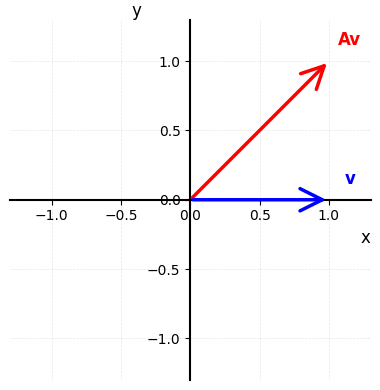

v  = [1, 0]
Av = [1, 1]
Av is not a multiple of v, so v is NOT an eigenvector.


In [15]:
try_vector(A, v)
try_vector(A, w)

In [18]:
check_answers(A, [
    (1, [0, 1]),  # (eigenvalue, eigenvector)
])

eigenvalue 1, eigenvector [0, 1]: correct!
You found all of this matrix's real eigenvalues (1 in total). Nice!


**Explain:** you should only be able to find **one** line of eigenvectors. Use the animation to explain why every other arrow gets knocked off its line.

Shear pushes every vector up by its x value. Vectors on the y-axis have x = 0, so they don't move. ANy vector with x not equal to zero gets slid upward, which tilts off its line.

### (e) Rotations

$A = \begin{bmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{bmatrix}$ **rotates** every vector by the angle $\theta$.

**Predict:** for which angles $\theta$ will *some* arrow stay on its own line? What are the eigenvalues for those angles?

only 0 degrees (eigenvalus equals 1, and every vector stays put), and 180 degrees (eigenvalue equals -1, every vector flips). Any other angle turns every arrow off its line.

Try **at least three** angles in degrees, including one where you think there are eigenvectors and one where you think there aren't. Run the cell once per angle.

In [22]:
angle = 180  # in degrees

A = pan.rotation_matrix_2d(angle, radians=False)
animator.animate_transform(A, vectors=[pan.Vector([1, 0]), pan.Vector([1, 1])])

(Animation: plays in Colab, not in the PDF.)

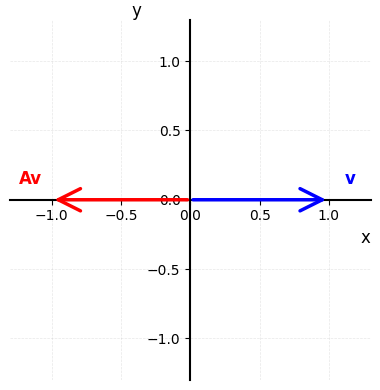

v  = [1, 0]
Av = [-1.0, 0.0]
Av = -1.0 * v, so v IS an eigenvector, with eigenvalue -1.0.


In [23]:
v = [1, 0]
try_vector(A, v)

**Explain:** list the angles you tried and what happened. For which values of $\theta$ (between $0^\circ$ and $360^\circ$) does a rotation have real eigenvectors, and what are the eigenvalues then?

at 0 degrees, nothing moved, so every vector is an eigenvector with eigenvaue equal to 1. At 90 degreew, every arrow turned sideways, so no eigenvectors. At 180 degrees, every arrow flipped to point the opposite way, so every vector is an eigenvector with eigenvalue equal to -1. So a rotation only has real eigenvectors at 0 and 180 degrees.

### (f) A matrix with no real eigenvalues

Now make your **own** $2 \times 2$ matrix with real entries that has **no** real eigenvalues. It **can't** be a rotation matrix (use other numbers than $0, 1, -1$).

*Hint:* you want a transformation that knocks **every** arrow off its line. The animation is a good way to check.

In [24]:
A = pan.Matrix([
    [1, -2],
    [3, 2],
])

animator.animate_transform(A, vectors=[pan.Vector([1, 0]), pan.Vector([0, 1]), pan.Vector([1, 1]), pan.Vector([1, -1])])

(Animation: plays in Colab, not in the PDF.)

In [ ]:
check_answers(A, [])

**Explain:** compute the characteristic polynomial $\det(A - \lambda I)$ of your matrix **by hand**, and explain why it has no real roots.

   $\det(A - \lambda I) = (1-\lambda)(2-\lambda) - (-2)(3) = \lambda^2 - 3\lambda + 2 + 6 = \lambda^2 - 3\lambda + 8$

   The discriminant is $(-3)^2 - 4(1)(8) = 9 - 32 = -23 < 0$, so there are no real roots and no real eigenvalues.

## Problem 3. Do row operations keep eigenvectors?

Pick one of the $2 \times 2$ matrices from Problem 1 or 2 (**not** the zero matrix) and copy it below. Then pick **one** row operation (keep exactly one line and delete the other two):

- `RowSwap(0, 1)` swaps row 0 and row 1.
- `RowScale(row, c)` multiplies a row by a number `c` (not 0).
- `RowAdd(target, source, c)` adds `c` times row `source` to row `target`.

Row operations only change the matrix, so $B$ is a **new** transformation.

**Predict:** will the eigenvectors you found for $A$ still be eigenvectors of $B$? Will the eigenvalues stay the same?

no. a row operation makes a dfferent transformation so the eigenvalues and vectors will prob change

In [25]:
half = pan.Fraction(1, 2)
A = pan.Matrix([
    [half, half],
    [half, half],
])
eigenvector_of_A = [1, 1]  # one you found earlier

op = RowScale(0, 2)

B = op.apply(A)
print("B =")
print(B)

B =
[[1, 1],
 [1/2, 1/2]]


In [26]:
animator.animate_transform(A, vectors=[pan.Vector(eigenvector_of_A)])

(Animation: plays in Colab, not in the PDF.)

In [27]:
animator.animate_transform(B, vectors=[pan.Vector(eigenvector_of_A)])

(Animation: plays in Colab, not in the PDF.)

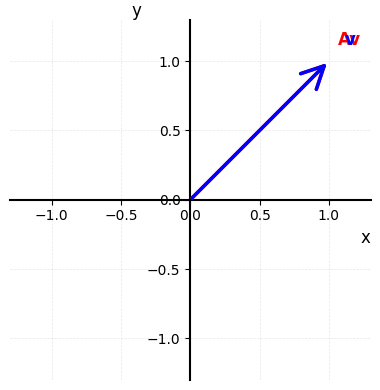

v  = [1, 1]
Av = [1, 1]
Av = 1 * v, so v IS an eigenvector, with eigenvalue 1.


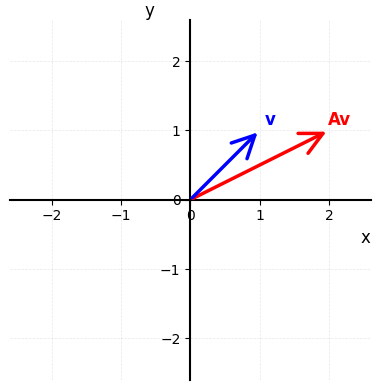

v  = [1, 1]
Av = [2, 1]
Av is not a multiple of v, so v is NOT an eigenvector.


In [28]:
try_vector(A, eigenvector_of_A)
try_vector(B, eigenvector_of_A)

Now find the eigenvalues of $B$ **by hand**: compute $\det(B - \lambda I)$ and solve for $\lambda$. At least one of them should be **different** from all of $A$'s eigenvalues; if not, go back and pick a different row operation.

*Hint:* if your eigenvalues have square roots in them, the eigenvectors will too, and they'll be hard to type. Pick a different row operation. `RowScale` on the shear or on the projection gives whole numbers or simple fractions.

**Your work for $\det(B - \lambda I)$ and the eigenvalues of $B$:**

$B = \begin{bmatrix}1 & 1\\ \frac12 & \frac12\end{bmatrix}$

$\det(B - \lambda I) = (1-\lambda)(\tfrac12-\lambda) - \tfrac12 = \lambda^2 - \tfrac32\lambda = \lambda(\lambda - \tfrac32)$

So the eigenvalues of $B$ are $\lambda = 0$ and $\lambda = \tfrac32$. A's eigenvalues were 1 and 0, so $\tfrac32$ is new.
Then use the animation of $B$ and `try_vector` to find an eigenvector for one of your new eigenvalues.

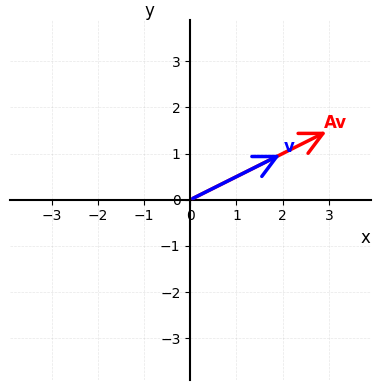

v  = [2, 1]
Av = [3, 3/2]
Av = 3/2 * v, so v IS an eigenvector, with eigenvalue 3/2.


In [29]:
v = [2, 1]
try_vector(B, v)

In [30]:
check_answers(B, [
    (pan.Fraction(3, 2), [2, 1]),   # (eigenvalue, eigenvector)
])

eigenvalue 3/2, eigenvector [2, 1]: correct!
You found 1 of this matrix's 2 real eigenvalue(s). Keep looking!


**Finish the sentence:** "When you do a single row operation to a matrix $A$, then the eigenvalues **\_\_\_\_\_\_\_\_\_\_** and the eigenvectors **\_\_\_\_\_\_\_\_\_\_**."

When you do a single row operation to a matrix A, then the eigenvalues can change and the eigenvectors can change too.

## Challenge: the mystery transformation

The hidden cell below builds a mystery $2 \times 2$ matrix `M` and plays its animation. **Don't open the hidden cell!** Just run it and watch.

This time there are no blanks: **write the code yourself.**

1. Write your **own** `animator.animate_transform(...)` call that animates `M` on vectors you choose, to hunt for an arrow that stays on its line. Use as many cells and tries as you like.
2. When you think you've found one, test it with `try_vector(M, ...)`, then record it with `check_answers(M, [...])`.

**Rules:** do **not** use `pan.eigen()`, `pan.eigen_qr()`, `pan.characteristic_polynomial()`, or `print(M)`. Find at least **one** eigenvector and its eigenvalue by experimenting. Bonus: find both!

*Hint:* scroll up to Problem 1 to see how the animation and `try_vector` calls were written.

In [31]:
# @title Mystery transformation (run me, but don't peek!)
M = pan.Matrix([[4, -2], [1, 1]])
animator.animate_transform(M)

(Animation: plays in Colab, not in the PDF.)

In [ ]:
animator.animate_transform(M, vectors=[
    pan.Vector([1, 0]),
    pan.Vector([0, 1]),
    pan.Vector([1, 1]),
    pan.Vector([1, -1]),
    pan.Vector([1, 2]),
    pan.Vector([2, 1]),
])

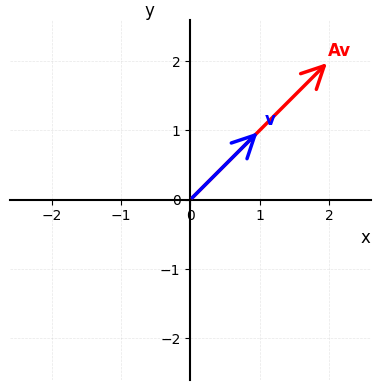

v  = [1, 1]
Av = [2, 2]
Av = 2 * v, so v IS an eigenvector, with eigenvalue 2.


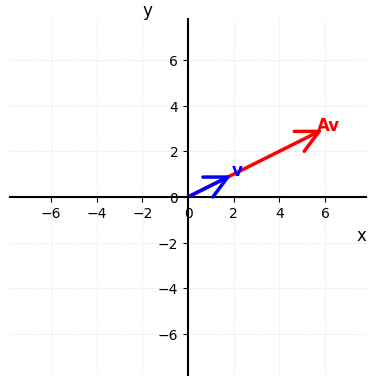

v  = [2, 1]
Av = [6, 3]
Av = 3 * v, so v IS an eigenvector, with eigenvalue 3.
eigenvalue 2, eigenvector [1, 1]: correct!
eigenvalue 3, eigenvector [2, 1]: correct!
You found all of this matrix's real eigenvalues (2 in total). Nice!


In [33]:
try_vector(M, [1, 1])
try_vector(M, [2, 1])

check_answers(M, [
    (2, [1, 1]),
    (3, [2, 1]),
])

**Explain:** describe how you found your eigenvector. What did you see in the animation that told you it was one?

I animated M on a bunch of vectors ([1, 0], [0, 1], [1, 1], [1, −1], [1, 2], [2, 1]) and watched which arrows stayed on their own line. Most of them got turned in a new direction, but [1, 1] and [2, 1] kept pointing the same way and just got longer. [1, 1] doubled in length and [2, 1] tripled. try_vector confirmed M[1, 1] = 2[1, 1] and M[2, 1] = 3[2, 1], so the eigenvals are 2 and 3.

## Export to PDF

When you've finished everything above:

1. **Save** the notebook (**File → Save**, or Ctrl/Cmd + S). The PDF is made from the *saved* copy in your Drive.
2. Click the ▶ button on the cell below. The first time, it spends a few minutes installing the PDF tools before making your PDF.

Your PDF will download to your computer and also be saved in the main folder of your Google Drive (**My Drive**). The setup and export cells won't show up in the PDF.

In [41]:
# @title Export to PDF
import shutil

from google.colab import files


def pdf_tools_ready():
    return shutil.which("xelatex") is not None and shutil.which("pandoc") is not None


# Install the PDF tools (LaTeX + pandoc) the first time this runs. It takes a few minutes.
if not pdf_tools_ready():
    print("Installing the PDF tools. This takes a few minutes, but only the first time...")
    !apt-get update -qq > /dev/null
    !DEBIAN_FRONTEND=noninteractive apt-get install -y -qq texlive-xetex texlive-fonts-recommended texlive-latex-extra texlive-plain-generic pandoc > /dev/null

NOTEBOOK = find_notebook()

if not pdf_tools_ready():
    print("Installing the PDF tools failed (see the messages above). Run this cell again.")
elif NOTEBOOK is None:
    print("Couldn't find your saved copy of this notebook in Drive.")
    print("Choose File > Save a copy in Drive, then work in that copy.")
else:
    # Copy the saved notebook out of Drive and convert it here. The PDF shows code and
    # outputs, hides the In [ ]: prompts, and leaves out the setup and export cells.
    LOCAL = f"/content/{NOTEBOOK_NAME}.ipynb"
    PDF = f"/content/{NOTEBOOK_NAME}.pdf"
    !rm -f "{PDF}"
    !cp "{NOTEBOOK}" "{LOCAL}"
    !jupyter nbconvert --to PDF "{LOCAL}" --log-level=ERROR --TemplateExporter.exclude_input_prompt=True --TemplateExporter.exclude_output_prompt=True --TagRemovePreprocessor.enabled=True --TagRemovePreprocessor.remove_cell_tags=remove_cell --TagRemovePreprocessor.remove_input_tags=remove_input

    if os.path.exists(PDF):
        !cp "{PDF}" "{MY_DRIVE}/"
        print("Done! Your PDF is in My Drive and is downloading now:", os.path.basename(PDF))
        files.download(PDF)
    else:
        print("Something went wrong making the PDF; see the messages above.")

Done! Your PDF is in My Drive and is downloading now: exploration_eigenvalues.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>